In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Notebook is inside src/
ROOT = Path.cwd().parent

PROCESSED_DIR = ROOT / "data" / "processed"
REPORT_DIR = ROOT / "reports"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Processed data folder:", PROCESSED_DIR)

Project root: c:\Users\anush\Customer-Journey-Reconstruction-Engine
Processed data folder: c:\Users\anush\Customer-Journey-Reconstruction-Engine\data\processed


In [3]:
DATA_FILE = PROCESSED_DIR / "customer_transactions.parquet"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Cannot find: {DATA_FILE}")

df = pd.read_parquet(DATA_FILE)

# Standardize data types
df["invoicedate"] = pd.to_datetime(df["invoicedate"])
df["customer_id"] = df["customer_id"].astype("Int64")
df["invoice"] = df["invoice"].astype(str)
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")
df["line_amount"] = pd.to_numeric(df["line_amount"], errors="coerce")

# Keep valid purchase records
df = df.dropna(
    subset=["customer_id", "invoice", "invoicedate", "quantity", "price"]
).copy()

df = df[
    (df["quantity"] > 0) &
    (df["price"] > 0) &
    (df["line_amount"] > 0)
].copy()

print("Shape:", df.shape)
print("Customers:", df["customer_id"].nunique())
print("Invoices:", df["invoice"].nunique())
print("Date range:", df["invoicedate"].min(), "to", df["invoicedate"].max())

display(df.head())

Shape: (779425, 19)
Customers: 5878
Invoices: 36969
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


,invoice,stockcode,description,quantity,invoicedate,price,customer_id,country,source_year,is_cancellation_invoice,is_return_quantity,is_invalid_date,is_nonpositive_quantity,is_nonpositive_price,line_amount,is_exact_duplicate,revenue,invoice_month,invoice_day
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,2009-2010,False,False,False,False,False,83.4,False,83.4,2009-12,2009-12-01
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-2010,False,False,False,False,False,81.0,False,81.0,2009-12,2009-12-01
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,2009-2010,False,False,False,False,False,81.0,False,81.0,2009-12,2009-12-01
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,2009-2010,False,False,False,False,False,100.8,False,100.8,2009-12,2009-12-01
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,2009-2010,False,False,False,False,False,30.0,False,30.0,2009-12,2009-12-01


In [4]:
orders = (
    df.groupby(["customer_id", "invoice"], as_index=False)
      .agg(
          order_date=("invoicedate", "min"),
          order_value=("line_amount", "sum"),
          total_quantity=("quantity", "sum"),
          unique_products=("stockcode", "nunique"),
          country=("country", "first")
      )
)

orders = orders.sort_values(
    ["customer_id", "order_date", "invoice"]
).reset_index(drop=True)

print("Order-level dataset:", orders.shape)
print("Unique customers:", orders["customer_id"].nunique())
print("Unique orders:", orders["invoice"].nunique())

display(orders.head())

Order-level dataset: (36969, 7)
Unique customers: 5878
Unique orders: 36969


,customer_id,invoice,order_date,order_value,total_quantity,unique_products,country
0,12346,491725,2009-12-14 08:34:00,45.0,10,1,United Kingdom
1,12346,491742,2009-12-14 11:00:00,22.5,5,1,United Kingdom
2,12346,491744,2009-12-14 11:02:00,22.5,5,1,United Kingdom
3,12346,492718,2009-12-18 10:47:00,22.5,5,1,United Kingdom
4,12346,492722,2009-12-18 10:55:00,1.0,1,1,United Kingdom


In [5]:
orders["days_since_previous_order"] = (
    orders.groupby("customer_id")["order_date"]
          .diff()
          .dt.total_seconds()
          .div(86400)
)

gap_summary = (
    orders.groupby("customer_id")["days_since_previous_order"]
          .agg(
              average_gap_days="mean",
              median_gap_days="median",
              gap_std_days="std"
          )
)

print("Purchase gap summary:")
display(gap_summary.describe().round(2))

print("Customers with at least one repeat order:",
      orders.loc[
          orders["days_since_previous_order"].notna(),
          "customer_id"
      ].nunique())

Purchase gap summary:


,average_gap_days,median_gap_days,gap_std_days
count,4255.00,4255.00,3311.00
mean,102.30,92.71,69.28
std,98.28,101.18,61.79
min,0.00,0.00,0.00
25%,38.58,28.08,26.78
50%,72.34,55.97,52.14
75%,129.84,118.19,90.42
max,714.15,714.15,495.75


Customers with at least one repeat order: 4255


In [6]:
reference_date = orders["order_date"].max() + pd.Timedelta(days=1)

customer_features = (
    orders.groupby("customer_id")
          .agg(
              total_orders=("invoice", "nunique"),
              total_spend=("order_value", "sum"),
              average_order_value=("order_value", "mean"),
              median_order_value=("order_value", "median"),
              total_quantity=("total_quantity", "sum"),
              average_quantity_per_order=("total_quantity", "mean"),
              average_products_per_order=("unique_products", "mean"),
              first_purchase=("order_date", "min"),
              last_purchase=("order_date", "max"),
              countries=("country", "nunique")
          )
)

customer_features["recency_days"] = (
    reference_date - customer_features["last_purchase"]
).dt.total_seconds() / 86400

customer_features["customer_lifetime_days"] = (
    customer_features["last_purchase"]
    - customer_features["first_purchase"]
).dt.total_seconds() / 86400

customer_features["orders_per_30_days"] = (
    30 * (customer_features["total_orders"] - 1)
    / customer_features["customer_lifetime_days"].replace(0, np.nan)
)

customer_features = customer_features.join(gap_summary)

print("Customer feature table:", customer_features.shape)
display(customer_features.head(10))

Customer feature table: (5878, 16)


,total_orders,total_spend,average_order_value,median_order_value,total_quantity,average_quantity_per_order,average_products_per_order,first_purchase,last_purchase,countries,recency_days,customer_lifetime_days,orders_per_30_days,average_gap_days,median_gap_days,gap_std_days
customer_id,,,,,,,,,,,,,,,,
12346,12,77556.46,6463.038333,22.500,74285,6190.416667,2.833333,2009-12-14 08:34:00,2011-01-18 10:01:00,1,326.117361,400.060417,0.824875,36.369129,7.986111,65.514508
12347,8,4921.53,615.191250,598.220,2967,370.875000,27.750000,2010-10-31 14:20:00,2011-12-07 15:52:00,1,2.873611,402.063889,0.522305,57.437698,53.824306,19.056884
12348,5,2019.40,403.880000,310.000,2714,542.800000,9.400000,2010-09-27 14:59:00,2011-09-25 13:13:00,1,75.984028,362.926389,0.330646,90.731597,75.088542,57.548389
12349,4,4428.69,1107.172500,1235.570,1624,406.000000,43.750000,2010-04-29 13:20:00,2011-11-21 09:51:00,1,19.124306,570.854861,0.157658,190.284954,162.934722,186.610348
12350,1,334.40,334.400000,334.400,197,197.000000,17.000000,2011-02-02 16:01:00,2011-02-02 16:01:00,1,310.867361,0.000000,NaN,NaN,NaN,NaN
12351,1,300.93,300.930000,300.930,261,261.000000,21.000000,2010-11-29 15:23:00,2010-11-29 15:23:00,1,375.893750,0.000000,NaN,NaN,NaN,NaN
12352,10,2849.84,284.984000,233.150,724,72.400000,10.100000,2010-11-12 10:20:00,2011-11-03 14:37:00,1,36.925694,356.178472,0.758047,39.575386,16.005556,58.483040
12353,2,406.76,203.380000,203.380,212,106.000000,12.000000,2010-10-27 12:44:00,2011-05-19 17:47:00,1,204.793750,204.210417,0.146907,204.210417,204.210417,NaN
12354,1,1079.40,1079.400000,1079.400,530,530.000000,58.000000,2011-04-21 13:11:00,2011-04-21 13:11:00,1,232.985417,0.000000,NaN,NaN,NaN,NaN


In [7]:
reference_date = orders["order_date"].max() + pd.Timedelta(days=1)

customer_features = (
    orders.groupby("customer_id")
          .agg(
              total_orders=("invoice", "nunique"),
              total_spend=("order_value", "sum"),
              average_order_value=("order_value", "mean"),
              median_order_value=("order_value", "median"),
              total_quantity=("total_quantity", "sum"),
              average_quantity_per_order=("total_quantity", "mean"),
              average_products_per_order=("unique_products", "mean"),
              first_purchase=("order_date", "min"),
              last_purchase=("order_date", "max"),
              countries=("country", "nunique")
          )
)

customer_features["recency_days"] = (
    reference_date - customer_features["last_purchase"]
).dt.total_seconds() / 86400

customer_features["customer_lifetime_days"] = (
    customer_features["last_purchase"]
    - customer_features["first_purchase"]
).dt.total_seconds() / 86400

customer_features["orders_per_30_days"] = (
    30 * (customer_features["total_orders"] - 1)
    / customer_features["customer_lifetime_days"].replace(0, np.nan)
)

customer_features = customer_features.join(gap_summary)

print("Customer feature table:", customer_features.shape)
display(customer_features.head(10))

Customer feature table: (5878, 16)


,total_orders,total_spend,average_order_value,median_order_value,total_quantity,average_quantity_per_order,average_products_per_order,first_purchase,last_purchase,countries,recency_days,customer_lifetime_days,orders_per_30_days,average_gap_days,median_gap_days,gap_std_days
customer_id,,,,,,,,,,,,,,,,
12346,12,77556.46,6463.038333,22.500,74285,6190.416667,2.833333,2009-12-14 08:34:00,2011-01-18 10:01:00,1,326.117361,400.060417,0.824875,36.369129,7.986111,65.514508
12347,8,4921.53,615.191250,598.220,2967,370.875000,27.750000,2010-10-31 14:20:00,2011-12-07 15:52:00,1,2.873611,402.063889,0.522305,57.437698,53.824306,19.056884
12348,5,2019.40,403.880000,310.000,2714,542.800000,9.400000,2010-09-27 14:59:00,2011-09-25 13:13:00,1,75.984028,362.926389,0.330646,90.731597,75.088542,57.548389
12349,4,4428.69,1107.172500,1235.570,1624,406.000000,43.750000,2010-04-29 13:20:00,2011-11-21 09:51:00,1,19.124306,570.854861,0.157658,190.284954,162.934722,186.610348
12350,1,334.40,334.400000,334.400,197,197.000000,17.000000,2011-02-02 16:01:00,2011-02-02 16:01:00,1,310.867361,0.000000,NaN,NaN,NaN,NaN
12351,1,300.93,300.930000,300.930,261,261.000000,21.000000,2010-11-29 15:23:00,2010-11-29 15:23:00,1,375.893750,0.000000,NaN,NaN,NaN,NaN
12352,10,2849.84,284.984000,233.150,724,72.400000,10.100000,2010-11-12 10:20:00,2011-11-03 14:37:00,1,36.925694,356.178472,0.758047,39.575386,16.005556,58.483040
12353,2,406.76,203.380000,203.380,212,106.000000,12.000000,2010-10-27 12:44:00,2011-05-19 17:47:00,1,204.793750,204.210417,0.146907,204.210417,204.210417,NaN
12354,1,1079.40,1079.400000,1079.400,530,530.000000,58.000000,2011-04-21 13:11:00,2011-04-21 13:11:00,1,232.985417,0.000000,NaN,NaN,NaN,NaN


In [8]:
product_diversity = (
    df.groupby("customer_id")
      .agg(
          unique_products_ever=("stockcode", "nunique"),
          unique_descriptions=("description", "nunique")
      )
)

customer_features = customer_features.join(product_diversity)

display(
    customer_features[
        [
            "total_orders",
            "total_spend",
            "unique_products_ever",
            "average_products_per_order"
        ]
    ].head(10)
)

,total_orders,total_spend,unique_products_ever,average_products_per_order
customer_id,,,,
12346,12,77556.46,27,2.833333
12347,8,4921.53,126,27.750000
12348,5,2019.40,25,9.400000
12349,4,4428.69,138,43.750000
12350,1,334.40,17,17.000000
12351,1,300.93,21,21.000000
12352,10,2849.84,70,10.100000
12353,2,406.76,23,12.000000
12354,1,1079.40,58,58.000000


In [9]:
rfm = customer_features[
    ["recency_days", "total_orders", "total_spend"]
].copy()

# Higher recency score means more recent purchase
rfm["R_score"] = pd.qcut(
    rfm["recency_days"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["total_orders"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["total_spend"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_score"] = (
    rfm["R_score"].astype(str) +
    rfm["F_score"].astype(str) +
    rfm["M_score"].astype(str)
)

customer_features = customer_features.join(
    rfm[["R_score", "F_score", "M_score", "RFM_score"]]
)

display(customer_features.head(10))

,total_orders,total_spend,average_order_value,median_order_value,total_quantity,average_quantity_per_order,average_products_per_order,first_purchase,last_purchase,countries,...,orders_per_30_days,average_gap_days,median_gap_days,gap_std_days,unique_products_ever,unique_descriptions,R_score,F_score,M_score,RFM_score
customer_id,,,,,,,,,,,,,,,,,,,,,
12346,12,77556.46,6463.038333,22.500,74285,6190.416667,2.833333,2009-12-14 08:34:00,2011-01-18 10:01:00,1,...,0.824875,36.369129,7.986111,65.514508,27,26,2,5,5,255
12347,8,4921.53,615.191250,598.220,2967,370.875000,27.750000,2010-10-31 14:20:00,2011-12-07 15:52:00,1,...,0.522305,57.437698,53.824306,19.056884,126,126,5,4,5,545
12348,5,2019.40,403.880000,310.000,2714,542.800000,9.400000,2010-09-27 14:59:00,2011-09-25 13:13:00,1,...,0.330646,90.731597,75.088542,57.548389,25,28,3,4,4,344
12349,4,4428.69,1107.172500,1235.570,1624,406.000000,43.750000,2010-04-29 13:20:00,2011-11-21 09:51:00,1,...,0.157658,190.284954,162.934722,186.610348,138,145,5,3,5,535
12350,1,334.40,334.400000,334.400,197,197.000000,17.000000,2011-02-02 16:01:00,2011-02-02 16:01:00,1,...,NaN,NaN,NaN,NaN,17,17,2,1,2,212
12351,1,300.93,300.930000,300.930,261,261.000000,21.000000,2010-11-29 15:23:00,2010-11-29 15:23:00,1,...,NaN,NaN,NaN,NaN,21,21,2,1,2,212
12352,10,2849.84,284.984000,233.150,724,72.400000,10.100000,2010-11-12 10:20:00,2011-11-03 14:37:00,1,...,0.758047,39.575386,16.005556,58.483040,70,70,4,5,4,454
12353,2,406.76,203.380000,203.380,212,106.000000,12.000000,2010-10-27 12:44:00,2011-05-19 17:47:00,1,...,0.146907,204.210417,204.210417,NaN,23,23,2,2,2,222
12354,1,1079.40,1079.400000,1079.400,530,530.000000,58.000000,2011-04-21 13:11:00,2011-04-21 13:11:00,1,...,NaN,NaN,NaN,NaN,58,58,2,1,3,213


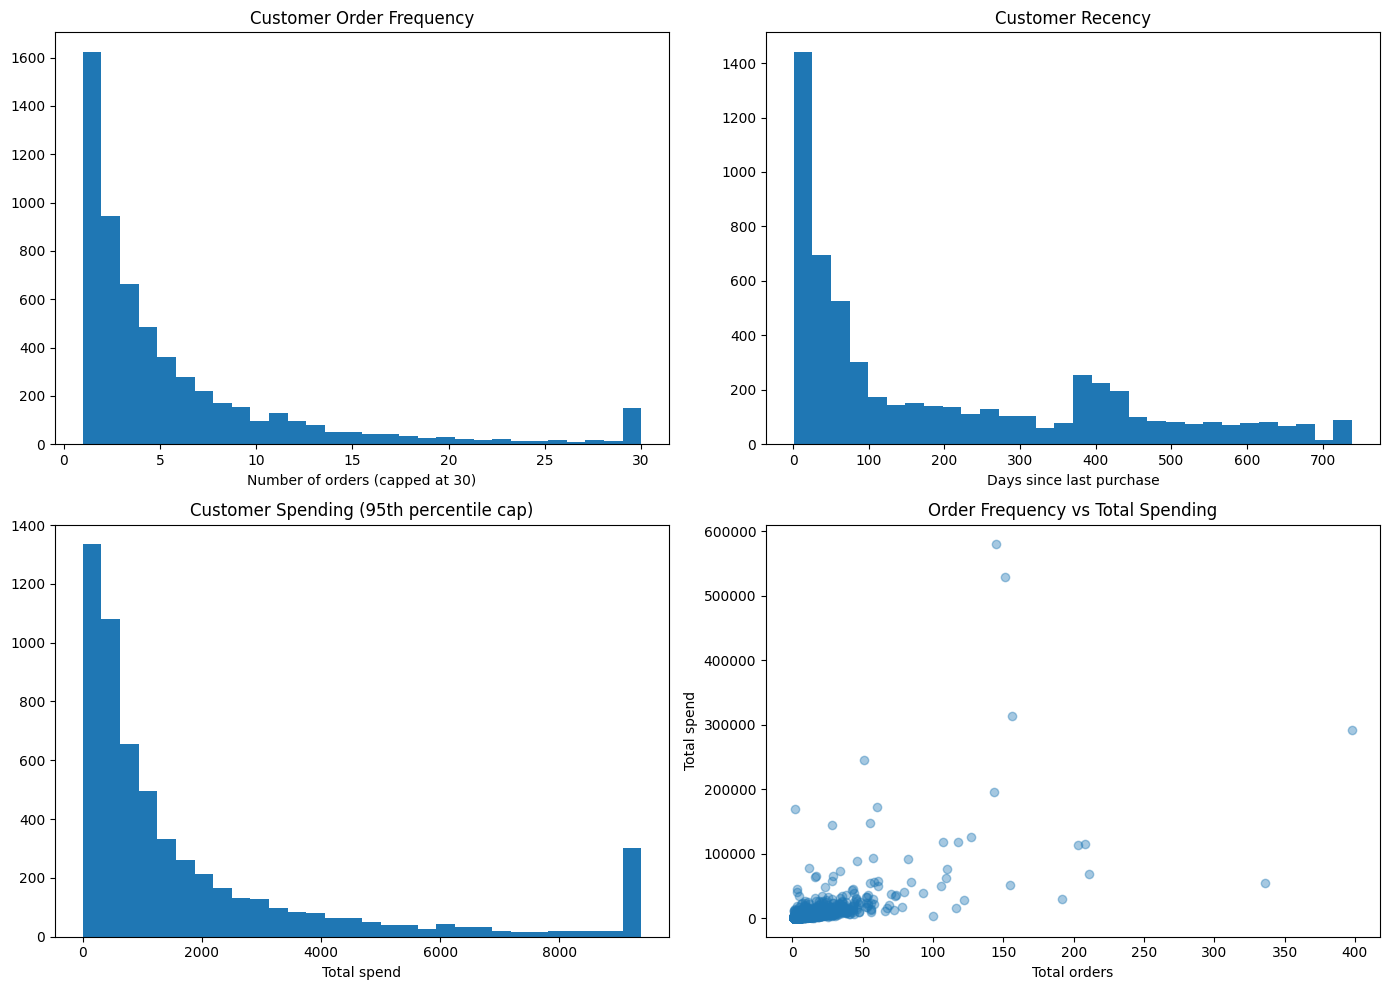

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

axes[0, 0].hist(
    customer_features["total_orders"].clip(upper=30),
    bins=30
)
axes[0, 0].set_title("Customer Order Frequency")
axes[0, 0].set_xlabel("Number of orders (capped at 30)")

axes[0, 1].hist(
    customer_features["recency_days"],
    bins=30
)
axes[0, 1].set_title("Customer Recency")
axes[0, 1].set_xlabel("Days since last purchase")

axes[1, 0].hist(
    customer_features["total_spend"].clip(
        upper=customer_features["total_spend"].quantile(0.95)
    ),
    bins=30
)
axes[1, 0].set_title("Customer Spending (95th percentile cap)")
axes[1, 0].set_xlabel("Total spend")

axes[1, 1].scatter(
    customer_features["total_orders"],
    customer_features["total_spend"],
    alpha=0.4
)
axes[1, 1].set_title("Order Frequency vs Total Spending")
axes[1, 1].set_xlabel("Total orders")
axes[1, 1].set_ylabel("Total spend")

plt.tight_layout()
plt.show()

In [11]:
rfm_distribution = (
    customer_features.groupby(
        ["R_score", "F_score", "M_score"],
        observed=True
    )
    .size()
    .reset_index(name="customer_count")
    .sort_values("customer_count", ascending=False)
)

print("Most common RFM combinations:")
display(rfm_distribution.head(15))

print("\nRFM score counts:")
display(customer_features["RFM_score"].value_counts().head(15))

Most common RFM combinations:


,R_score,F_score,M_score,customer_count
113,5,5,5,467
0,1,1,1,318
91,4,5,5,246
5,1,2,1,172
23,2,1,1,165
63,3,4,4,165
1,1,1,2,152
87,4,4,4,147
6,1,2,2,135
69,3,5,5,135



RFM score counts:


RFM_score
555    467
111    318
455    246
121    172
211    165
344    165
112    152
444    147
122    135
355    135
544    130
221    122
222    121
233    110
433    108
Name: count, dtype: int64

In [12]:
# Create monthly snapshot dates covering the dataset period.
monthly_periods = pd.period_range(
    start=orders["order_date"].min().to_period("M"),
    end=orders["order_date"].max().to_period("M"),
    freq="M"
)

snapshot_rows = []

for period in monthly_periods:

    # End of this month
    snapshot_date = period.end_time

    # Use transactions available up to this snapshot
    history = orders[
        orders["order_date"] <= snapshot_date
    ].copy()

    # Only customers with a purchase in the previous 365 days
    active_history = history[
        history["order_date"] >
        snapshot_date - pd.Timedelta(days=365)
    ]

    for customer_id, recent in active_history.groupby("customer_id"):

        # All historical orders for this customer up to snapshot
        customer_history = history[
            history["customer_id"] == customer_id
        ]

        # Recent time windows
        last_30 = recent[
            recent["order_date"] >
            snapshot_date - pd.Timedelta(days=30)
        ]

        last_90 = recent[
            recent["order_date"] >
            snapshot_date - pd.Timedelta(days=90)
        ]

        last_365 = recent

        previous_gaps = (
            customer_history["order_date"]
            .sort_values()
            .diff()
            .dt.total_seconds()
            .div(86400)
            .dropna()
        )

        last_order_date = customer_history["order_date"].max()
        first_order_date = customer_history["order_date"].min()

        snapshot_rows.append({
            "customer_id": customer_id,
            "snapshot_date": snapshot_date,

            # Recency
            "recency_days": (
                snapshot_date - last_order_date
            ).total_seconds() / 86400,

            # Lifetime behavior
            "lifetime_orders": customer_history["invoice"].nunique(),
            "lifetime_spend": customer_history["order_value"].sum(),
            "lifetime_avg_order_value": (
                customer_history["order_value"].mean()
            ),
            "customer_age_days": (
                snapshot_date - first_order_date
            ).total_seconds() / 86400,

            # Last 30 days
            "orders_30d": last_30["invoice"].nunique(),
            "spend_30d": last_30["order_value"].sum(),
            "quantity_30d": last_30["total_quantity"].sum(),

            # Last 90 days
            "orders_90d": last_90["invoice"].nunique(),
            "spend_90d": last_90["order_value"].sum(),
            "avg_order_value_90d": (
                last_90["order_value"].mean()
                if len(last_90) > 0 else 0
            ),

            # Last 365 days
            "orders_365d": last_365["invoice"].nunique(),
            "spend_365d": last_365["order_value"].sum(),
            "avg_order_value_365d": (
                last_365["order_value"].mean()
                if len(last_365) > 0 else 0
            ),

            # Purchase consistency
            "average_gap_days": (
                previous_gaps.mean()
                if len(previous_gaps) > 0 else np.nan
            ),
            "median_gap_days": (
                previous_gaps.median()
                if len(previous_gaps) > 0 else np.nan
            ),
            "gap_std_days": (
                previous_gaps.std()
                if len(previous_gaps) > 1 else np.nan
            ),

            # Order size and variety
            "avg_quantity_per_order_90d": (
                last_90["total_quantity"].mean()
                if len(last_90) > 0 else 0
            ),
            "avg_products_per_order_90d": (
                last_90["unique_products"].mean()
                if len(last_90) > 0 else 0
            )
        })

snapshots = pd.DataFrame(snapshot_rows)

snapshots = snapshots.sort_values(
    ["customer_id", "snapshot_date"]
).reset_index(drop=True)

print("Snapshot dataset shape:", snapshots.shape)
print("Unique customers:", snapshots["customer_id"].nunique())
print("Snapshot months:", snapshots["snapshot_date"].nunique())

display(snapshots.head(10))

Snapshot dataset shape: (88515, 21)
Unique customers: 5878
Snapshot months: 25


,customer_id,snapshot_date,recency_days,lifetime_orders,lifetime_spend,lifetime_avg_order_value,customer_age_days,orders_30d,spend_30d,quantity_30d,...,spend_90d,avg_order_value_90d,orders_365d,spend_365d,avg_order_value_365d,average_gap_days,median_gap_days,gap_std_days,avg_quantity_per_order_90d,avg_products_per_order_90d
0,12346,2009-12-31 23:59:59.999999999,13.545139,5,113.50,22.700000,17.643056,5,113.50,26,...,113.50,22.700000,5,113.50,22.700000,1.024479,0.053472,1.977276,5.200000,1.0
1,12346,2010-01-31 23:59:59.999999999,9.437500,9,203.50,22.611111,48.643056,4,90.00,20,...,203.50,22.611111,9,203.50,22.611111,4.900694,2.045486,6.299038,5.111111,1.0
2,12346,2010-02-28 23:59:59.999999999,37.437500,9,203.50,22.611111,76.643056,0,0.00,0,...,203.50,22.611111,9,203.50,22.611111,4.900694,2.045486,6.299038,5.111111,1.0
3,12346,2010-03-31 23:59:59.999999999,29.452778,10,230.55,23.055000,107.643056,1,27.05,5,...,117.05,23.410000,10,230.55,23.055000,8.687809,3.989583,12.798369,5.000000,1.8
4,12346,2010-04-30 23:59:59.999999999,59.452778,10,230.55,23.055000,137.643056,0,0.00,0,...,27.05,27.050000,10,230.55,23.055000,8.687809,3.989583,12.798369,5.000000,5.0
5,12346,2010-05-31 23:59:59.999999999,90.452778,10,230.55,23.055000,168.643056,0,0.00,0,...,0.00,0.000000,10,230.55,23.055000,8.687809,3.989583,12.798369,0.000000,0.0
6,12346,2010-06-30 23:59:59.999999999,2.421528,11,372.86,33.896364,198.643056,1,142.31,19,...,142.31,142.310000,11,372.86,33.896364,19.622153,5.987847,36.622360,19.000000,19.0
7,12346,2010-07-31 23:59:59.999999999,33.421528,11,372.86,33.896364,229.643056,0,0.00,0,...,142.31,142.310000,11,372.86,33.896364,19.622153,5.987847,36.622360,19.000000,19.0
8,12346,2010-08-31 23:59:59.999999999,64.421528,11,372.86,33.896364,260.643056,0,0.00,0,...,142.31,142.310000,11,372.86,33.896364,19.622153,5.987847,36.622360,19.000000,19.0
9,12346,2010-09-30 23:59:59.999999999,94.421528,11,372.86,33.896364,290.643056,0,0.00,0,...,0.00,0.000000,11,372.86,33.896364,19.622153,5.987847,36.622360,0.000000,0.0


In [13]:
snapshots = snapshots.sort_values(
    ["customer_id", "snapshot_date"]
).copy()

grouped = snapshots.groupby("customer_id")

# Change in order frequency compared with the previous monthly snapshot
snapshots["orders_90d_previous_month"] = (
    grouped["orders_90d"].shift(1)
)

snapshots["spend_90d_previous_month"] = (
    grouped["spend_90d"].shift(1)
)

snapshots["orders_90d_change"] = (
    snapshots["orders_90d"]
    - snapshots["orders_90d_previous_month"]
)

snapshots["spend_90d_change"] = (
    snapshots["spend_90d"]
    - snapshots["spend_90d_previous_month"]
)

# Relative changes; avoid division by zero
snapshots["orders_90d_pct_change"] = np.where(
    snapshots["orders_90d_previous_month"] > 0,
    (
        snapshots["orders_90d_change"]
        / snapshots["orders_90d_previous_month"]
    ) * 100,
    np.nan
)

snapshots["spend_90d_pct_change"] = np.where(
    snapshots["spend_90d_previous_month"] > 0,
    (
        snapshots["spend_90d_change"]
        / snapshots["spend_90d_previous_month"]
    ) * 100,
    np.nan
)

display(snapshots.head(10))

,customer_id,snapshot_date,recency_days,lifetime_orders,lifetime_spend,lifetime_avg_order_value,customer_age_days,orders_30d,spend_30d,quantity_30d,...,median_gap_days,gap_std_days,avg_quantity_per_order_90d,avg_products_per_order_90d,orders_90d_previous_month,spend_90d_previous_month,orders_90d_change,spend_90d_change,orders_90d_pct_change,spend_90d_pct_change
0,12346,2009-12-31 23:59:59.999999999,13.545139,5,113.50,22.700000,17.643056,5,113.50,26,...,0.053472,1.977276,5.200000,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,12346,2010-01-31 23:59:59.999999999,9.437500,9,203.50,22.611111,48.643056,4,90.00,20,...,2.045486,6.299038,5.111111,1.0,5.0,113.50,4.0,90.00,80.000000,79.295154
2,12346,2010-02-28 23:59:59.999999999,37.437500,9,203.50,22.611111,76.643056,0,0.00,0,...,2.045486,6.299038,5.111111,1.0,9.0,203.50,0.0,0.00,0.000000,0.000000
3,12346,2010-03-31 23:59:59.999999999,29.452778,10,230.55,23.055000,107.643056,1,27.05,5,...,3.989583,12.798369,5.000000,1.8,9.0,203.50,-4.0,-86.45,-44.444444,-42.481572
4,12346,2010-04-30 23:59:59.999999999,59.452778,10,230.55,23.055000,137.643056,0,0.00,0,...,3.989583,12.798369,5.000000,5.0,5.0,117.05,-4.0,-90.00,-80.000000,-76.890218
5,12346,2010-05-31 23:59:59.999999999,90.452778,10,230.55,23.055000,168.643056,0,0.00,0,...,3.989583,12.798369,0.000000,0.0,1.0,27.05,-1.0,-27.05,-100.000000,-100.000000
6,12346,2010-06-30 23:59:59.999999999,2.421528,11,372.86,33.896364,198.643056,1,142.31,19,...,5.987847,36.622360,19.000000,19.0,0.0,0.00,1.0,142.31,NaN,NaN
7,12346,2010-07-31 23:59:59.999999999,33.421528,11,372.86,33.896364,229.643056,0,0.00,0,...,5.987847,36.622360,19.000000,19.0,1.0,142.31,0.0,0.00,0.000000,0.000000
8,12346,2010-08-31 23:59:59.999999999,64.421528,11,372.86,33.896364,260.643056,0,0.00,0,...,5.987847,36.622360,19.000000,19.0,1.0,142.31,0.0,0.00,0.000000,0.000000
9,12346,2010-09-30 23:59:59.999999999,94.421528,11,372.86,33.896364,290.643056,0,0.00,0,...,5.987847,36.622360,0.000000,0.0,1.0,142.31,-1.0,-142.31,-100.000000,-100.000000


In [14]:
diversity_rows = []

for period in monthly_periods:
    snapshot_date = period.end_time
    window_start = snapshot_date - pd.Timedelta(days=365)

    window_df = df[
        (df["invoicedate"] > window_start) &
        (df["invoicedate"] <= snapshot_date)
    ]

    diversity = (
        window_df.groupby("customer_id")
                 .agg(
                     unique_products_365d=("stockcode", "nunique"),
                     unique_descriptions_365d=("description", "nunique")
                 )
                 .reset_index()
    )

    diversity["snapshot_date"] = snapshot_date
    diversity_rows.append(diversity)

diversity_features = pd.concat(
    diversity_rows,
    ignore_index=True
)

snapshots = snapshots.merge(
    diversity_features,
    on=["customer_id", "snapshot_date"],
    how="left"
)

snapshots[
    ["unique_products_365d", "unique_descriptions_365d"]
] = snapshots[
    ["unique_products_365d", "unique_descriptions_365d"]
].fillna(0)

display(
    snapshots[
        [
            "customer_id",
            "snapshot_date",
            "orders_90d",
            "spend_90d",
            "unique_products_365d"
        ]
    ].head(10)
)

,customer_id,snapshot_date,orders_90d,spend_90d,unique_products_365d
0,12346,2009-12-31 23:59:59.999999999,5,113.50,2
1,12346,2010-01-31 23:59:59.999999999,9,203.50,2
2,12346,2010-02-28 23:59:59.999999999,9,203.50,2
3,12346,2010-03-31 23:59:59.999999999,5,117.05,7
4,12346,2010-04-30 23:59:59.999999999,1,27.05,7
5,12346,2010-05-31 23:59:59.999999999,0,0.00,7
6,12346,2010-06-30 23:59:59.999999999,1,142.31,26
7,12346,2010-07-31 23:59:59.999999999,1,142.31,26
8,12346,2010-08-31 23:59:59.999999999,1,142.31,26
9,12346,2010-09-30 23:59:59.999999999,0,0.00,26


In [15]:
print("CUSTOMER-LEVEL FEATURES")
print("Shape:", customer_features.shape)
print("Unique customers:", customer_features.index.nunique())

print("\nMONTHLY SNAPSHOTS")
print("Shape:", snapshots.shape)
print("Unique customers:", snapshots["customer_id"].nunique())
print("Unique months:", snapshots["snapshot_date"].nunique())

# One row per customer per snapshot month
duplicate_snapshots = snapshots.duplicated(
    subset=["customer_id", "snapshot_date"]
).sum()

print("Duplicate customer-month rows:", duplicate_snapshots)

# Check basic logical conditions
print("\nLOGICAL CHECKS")
print("Negative recency values:", (snapshots["recency_days"] < 0).sum())
print("Negative order counts:", (snapshots["orders_90d"] < 0).sum())
print("Negative spend values:", (snapshots["spend_90d"] < 0).sum())

print("\nMissing values in snapshot features:")
display(
    snapshots.isna().sum().sort_values(ascending=False).head(15)
)

assert duplicate_snapshots == 0
assert (snapshots["recency_days"] >= 0).all()
assert (snapshots["orders_90d"] >= 0).all()
assert (snapshots["spend_90d"] >= 0).all()

print("\nBasic validation passed.")

CUSTOMER-LEVEL FEATURES
Shape: (5878, 22)
Unique customers: 5878

MONTHLY SNAPSHOTS
Shape: (88515, 29)
Unique customers: 5878
Unique months: 25
Duplicate customer-month rows: 0

LOGICAL CHECKS
Negative recency values: 0
Negative order counts: 0
Negative spend values: 0

Missing values in snapshot features:


gap_std_days                 43734
spend_90d_pct_change         39844
orders_90d_pct_change        39844
average_gap_days             27826
median_gap_days              27826
spend_90d_change              5878
spend_90d_previous_month      5878
orders_90d_previous_month     5878
orders_90d_change             5878
snapshot_date                    0
recency_days                     0
lifetime_orders                  0
customer_id                      0
avg_order_value_90d              0
spend_90d                        0
dtype: int64


Basic validation passed.


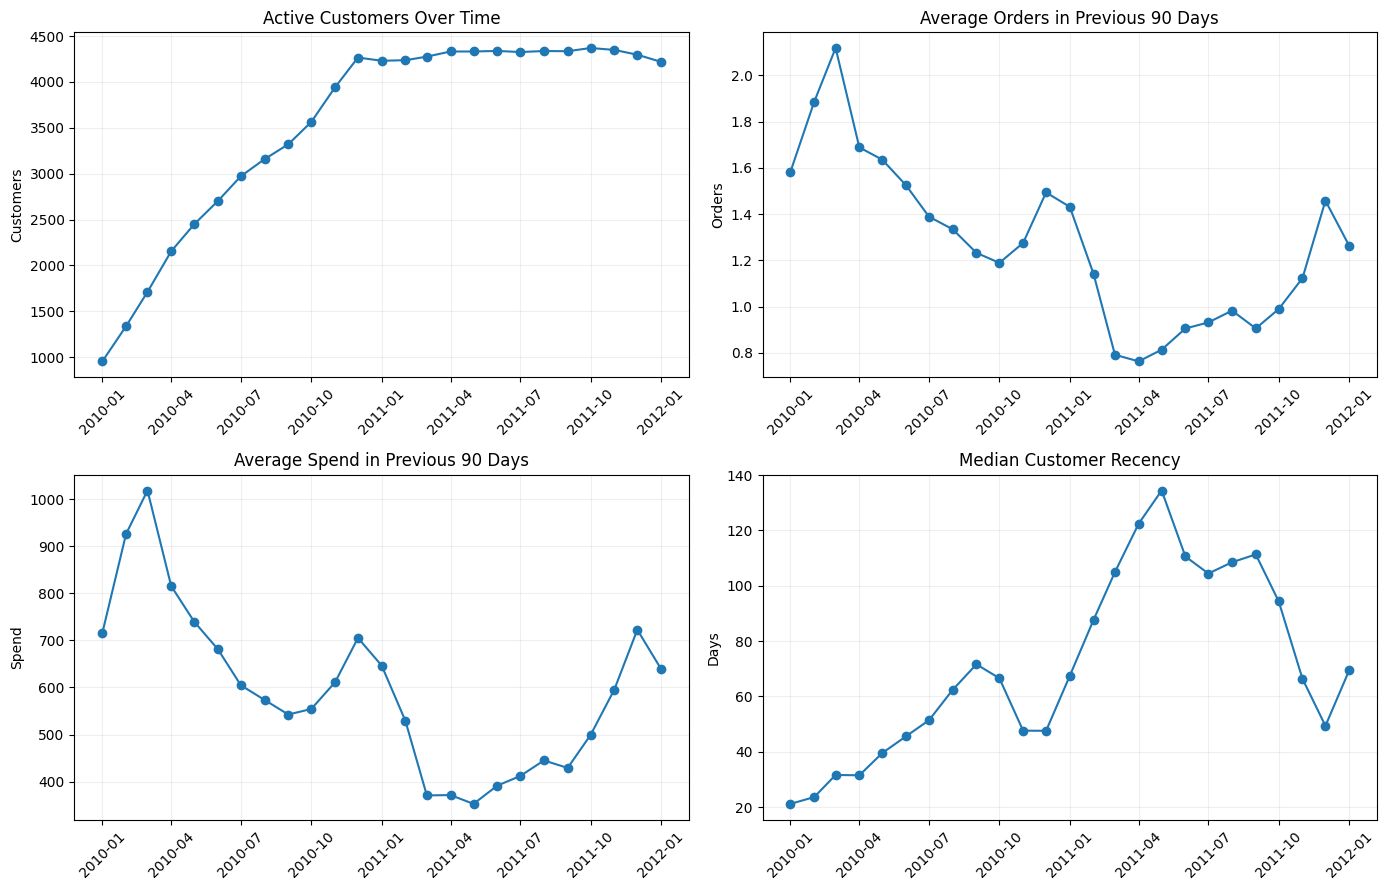

,snapshot_date,active_customers,average_orders_90d,average_spend_90d,median_recency
0,2009-12-31 23:59:59.999999999,955,1.583246,715.711005,21.163889
1,2010-01-31 23:59:59.999999999,1338,1.885650,926.238178,23.614236
2,2010-02-28 23:59:59.999999999,1712,2.118575,1018.613106,31.614931
3,2010-03-31 23:59:59.999999999,2155,1.688631,815.471044,31.488889
4,2010-04-30 23:59:59.999999999,2449,1.635361,739.804528,39.540972
5,2010-05-31 23:59:59.999999999,2703,1.524602,681.166179,45.582639
6,2010-06-30 23:59:59.999999999,2973,1.388833,604.621545,51.403472
7,2010-07-31 23:59:59.999999999,3159,1.334283,573.472146,62.389583
8,2010-08-31 23:59:59.999999999,3321,1.232460,542.464122,71.606944
9,2010-09-30 23:59:59.999999999,3564,1.189113,554.270082,66.566667


In [16]:
monthly_behavior = (
    snapshots.groupby("snapshot_date")
             .agg(
                 active_customers=("customer_id", "nunique"),
                 average_orders_90d=("orders_90d", "mean"),
                 average_spend_90d=("spend_90d", "mean"),
                 median_recency=("recency_days", "median")
             )
             .reset_index()
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(
    monthly_behavior["snapshot_date"],
    monthly_behavior["active_customers"],
    marker="o"
)
axes[0, 0].set_title("Active Customers Over Time")
axes[0, 0].set_ylabel("Customers")

axes[0, 1].plot(
    monthly_behavior["snapshot_date"],
    monthly_behavior["average_orders_90d"],
    marker="o"
)
axes[0, 1].set_title("Average Orders in Previous 90 Days")
axes[0, 1].set_ylabel("Orders")

axes[1, 0].plot(
    monthly_behavior["snapshot_date"],
    monthly_behavior["average_spend_90d"],
    marker="o"
)
axes[1, 0].set_title("Average Spend in Previous 90 Days")
axes[1, 0].set_ylabel("Spend")

axes[1, 1].plot(
    monthly_behavior["snapshot_date"],
    monthly_behavior["median_recency"],
    marker="o"
)
axes[1, 1].set_title("Median Customer Recency")
axes[1, 1].set_ylabel("Days")

for ax in axes.flat:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

display(monthly_behavior)

In [17]:
customer_features_path = (
    PROCESSED_DIR / "customer_behavioral_features.parquet"
)

snapshots_path = (
    PROCESSED_DIR / "customer_monthly_snapshots.parquet"
)

monthly_behavior_path = (
    PROCESSED_DIR / "monthly_customer_behavior.parquet"
)

customer_features.to_parquet(
    customer_features_path,
    index=True
)

snapshots.to_parquet(
    snapshots_path,
    index=False
)

monthly_behavior.to_parquet(
    monthly_behavior_path,
    index=False
)

print("Saved successfully:")
print(customer_features_path)
print(snapshots_path)
print(monthly_behavior_path)

Saved successfully:
c:\Users\anush\Customer-Journey-Reconstruction-Engine\data\processed\customer_behavioral_features.parquet
c:\Users\anush\Customer-Journey-Reconstruction-Engine\data\processed\customer_monthly_snapshots.parquet
c:\Users\anush\Customer-Journey-Reconstruction-Engine\data\processed\monthly_customer_behavior.parquet


In [18]:
report_path = REPORT_DIR / "day2_feature_engineering_report.md"

report = f"""
# Customer Journey Reconstruction Engine
## Day 2 — Customer Behavioral Feature Engineering

### Dataset
- Customer-level feature rows: {len(customer_features):,}
- Unique customers: {customer_features.index.nunique():,}
- Monthly snapshot rows: {len(snapshots):,}
- Unique customers in snapshots: {snapshots['customer_id'].nunique():,}
- Snapshot months: {snapshots['snapshot_date'].nunique():,}

### Overall customer features
Created:
- Total orders and total spend
- Average and median order value
- Total quantity and average quantity per order
- Average products per order
- First and last purchase dates
- Recency and customer lifetime
- Approximate order frequency
- Average, median and standard deviation of purchase gaps
- Product diversity
- RFM scores

### Monthly snapshot features
Created:
- Recency
- Lifetime orders and spend
- Orders, spend and quantity in the previous 30 days
- Orders and spend in the previous 90 days
- Orders and spend in the previous 365 days
- Average order value
- Purchase gap statistics
- Average quantity and product variety per order
- Product diversity over the previous 365 days
- Month-over-month changes in 90-day order and spend activity

### Snapshot methodology
Snapshots are created at month-end.
Features use transactions on or before each snapshot date.
Only customers with at least one purchase in the preceding
365 days are included in that month's snapshot.

### Important limitations
- The dataset covers a finite historical period.
- A customer absent from a snapshot may be inactive for more
  than 365 days; absence does not prove permanent churn.
- RFM scores are relative quintile-based scores.
- Purchase-frequency estimates are unreliable for customers
  with only one observed order.
- Monthly 90-day windows overlap.

### Next step
Discover customer behavioral states and transitions over time.
"""

report_path.write_text(report.strip(), encoding="utf-8")

print("Day 2 report saved:", report_path)

Day 2 report saved: c:\Users\anush\Customer-Journey-Reconstruction-Engine\reports\day2_feature_engineering_report.md
